# EDA

In [27]:
import pandas as pd

df = pd.read_csv('./data/regression_bonus_practice_data.csv')
df.head()


,index,number_of_siblings,direct_admission,CCA,learning_style,student_id,gender,tuition,final_test,n_male,n_female,age,hours_per_week,attendance_rate,sleep_time,wake_time,mode_of_transport,bag_color
0,0,0,Yes,Sports,Visual,ACN2BE,Female,No,69.0,14.0,2.0,16.0,10.0,91.0,22:00,6:00,private transport,yellow
1,1,2,No,Sports,Auditory,FGXIIZ,Female,No,47.0,4.0,19.0,16.0,7.0,94.0,22:30,6:30,private transport,green
2,2,0,Yes,NaN,Visual,B9AI9F,Male,No,85.0,14.0,2.0,15.0,8.0,92.0,22:30,6:30,private transport,white
3,3,1,No,Clubs,Auditory,FEVM1T,Female,Yes,64.0,2.0,20.0,15.0,18.0,NaN,21:00,5:00,public transport,yellow
4,4,0,No,Sports,Auditory,AXZN2E,Male,No,66.0,24.0,3.0,16.0,7.0,95.0,21:30,5:30,public transport,yellow


In [28]:
df['final_test'].isnull().head()

0    False
1    False
2    False
3    False
4    False
Name: final_test, dtype: bool

In [29]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 15900 entries, 0 to 15899
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   index               15900 non-null  int64  
 1   number_of_siblings  15900 non-null  int64  
 2   direct_admission    15900 non-null  str    
 3   CCA                 12071 non-null  str    
 4   learning_style      15900 non-null  str    
 5   student_id          15900 non-null  str    
 6   gender              15900 non-null  str    
 7   tuition             15900 non-null  str    
 8   final_test          15405 non-null  float64
 9   n_male              15900 non-null  float64
 10  n_female            15900 non-null  float64
 11  age                 15900 non-null  float64
 12  hours_per_week      15900 non-null  float64
 13  attendance_rate     15122 non-null  float64
 14  sleep_time          15900 non-null  str    
 15  wake_time           15900 non-null  str    
 16  mode_of_transpo

In [30]:
df.describe()

,index,number_of_siblings,final_test,n_male,n_female,age,hours_per_week,attendance_rate
count,15900.000000,15900.000000,15405.000000,15900.000000,15900.000000,15900.000000,15900.000000,15122.000000
mean,7949.500000,0.886541,67.165401,13.880000,8.906038,15.213459,10.312579,93.270268
std,4590.078975,0.751346,13.977879,6.552584,6.663852,1.758941,4.461861,7.984230
min,0.000000,0.000000,32.000000,0.000000,0.000000,-5.000000,0.000000,40.000000
25%,3974.750000,0.000000,56.000000,10.000000,4.000000,15.000000,7.000000,92.000000
50%,7949.500000,1.000000,68.000000,14.000000,8.000000,15.000000,9.000000,95.000000
75%,11924.250000,1.000000,78.000000,18.000000,13.000000,16.000000,14.000000,97.000000
max,15899.000000,2.000000,100.000000,31.000000,31.000000,16.000000,20.000000,100.000000


In [31]:
df.isnull().sum()

index                    0
number_of_siblings       0
direct_admission         0
CCA                   3829
learning_style           0
student_id               0
gender                   0
tuition                  0
final_test             495
n_male                   0
n_female                 0
age                      0
hours_per_week           0
attendance_rate        778
sleep_time               0
wake_time                0
mode_of_transport        0
bag_color                0
dtype: int64

In [32]:
int(df.duplicated().sum())

0

# Data Preparation

## Data Cleaning

### Filling empty cells

In [33]:
# CCA is a categorical column so we take null CCA as not having any CCA
df['CCA'] = df['CCA'].fillna(value="None")
# Since final_test is the label, we need to drop rows with missing labels
df.dropna(subset=['final_test'], inplace=True)
# Attendance has missing numerical values so the mean value is used for fillna
df['attendance_rate'] = df['attendance_rate'].fillna(df['attendance_rate'].mean(numeric_only=True))
# Check 
df.isnull().sum()

index                 0
number_of_siblings    0
direct_admission      0
CCA                   0
learning_style        0
student_id            0
gender                0
tuition               0
final_test            0
n_male                0
n_female              0
age                   0
hours_per_week        0
attendance_rate       0
sleep_time            0
wake_time             0
mode_of_transport     0
bag_color             0
dtype: int64

### Checking for mislabelled data within categorical columns

In [34]:
import math
import matplotlib.pyplot as plt
import seaborn as sns


Plotting 11 columns: ['number_of_siblings', 'direct_admission', 'CCA', 'learning_style', 'gender', 'tuition', 'age', 'sleep_time', 'wake_time', 'mode_of_transport', 'bag_color']


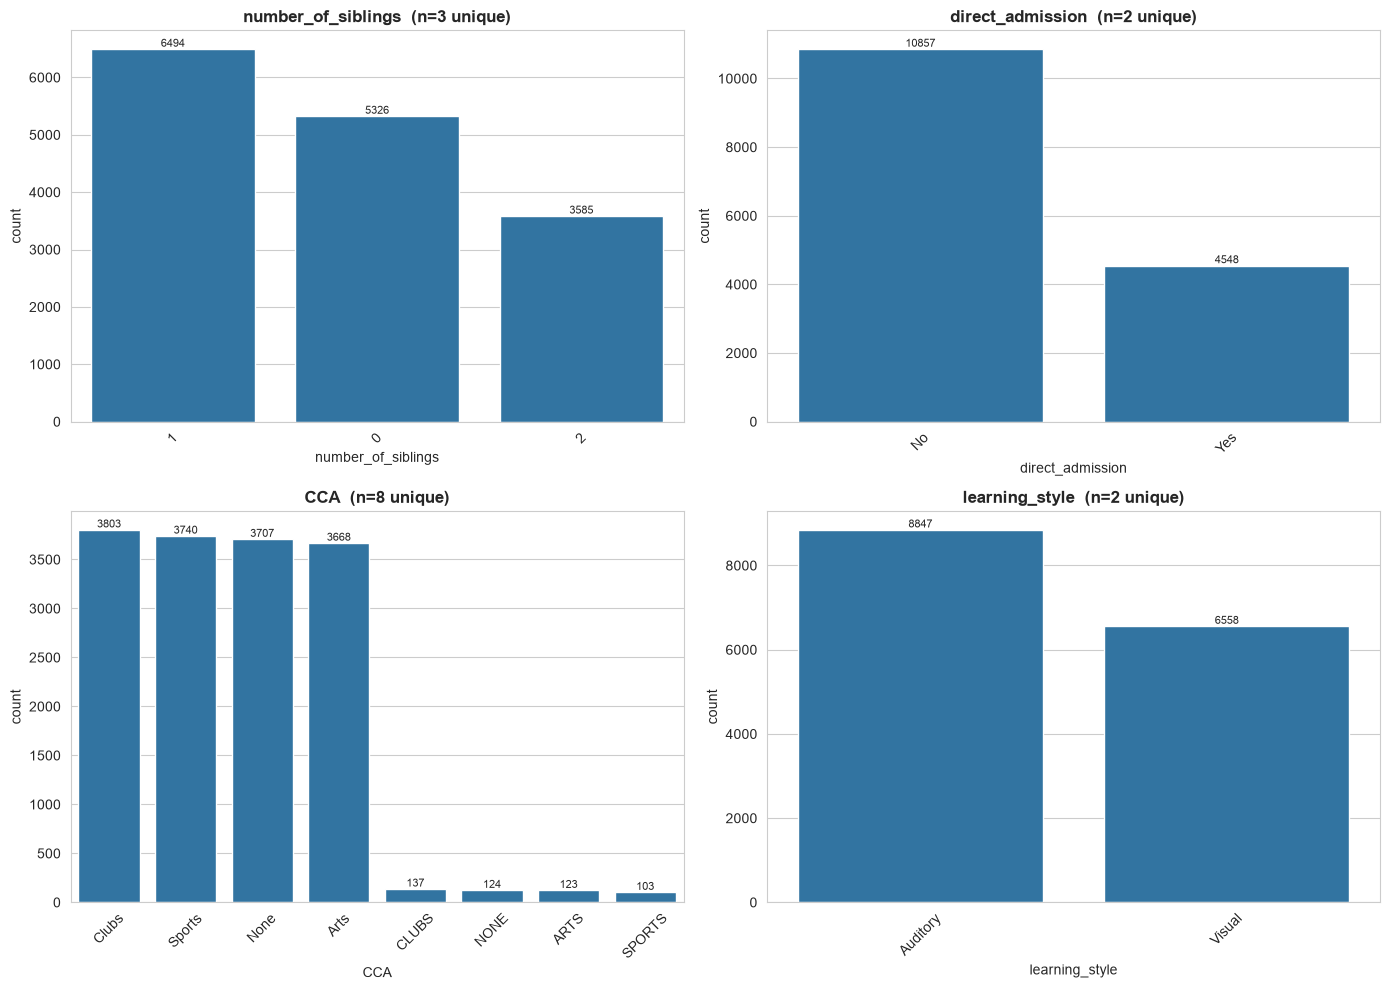

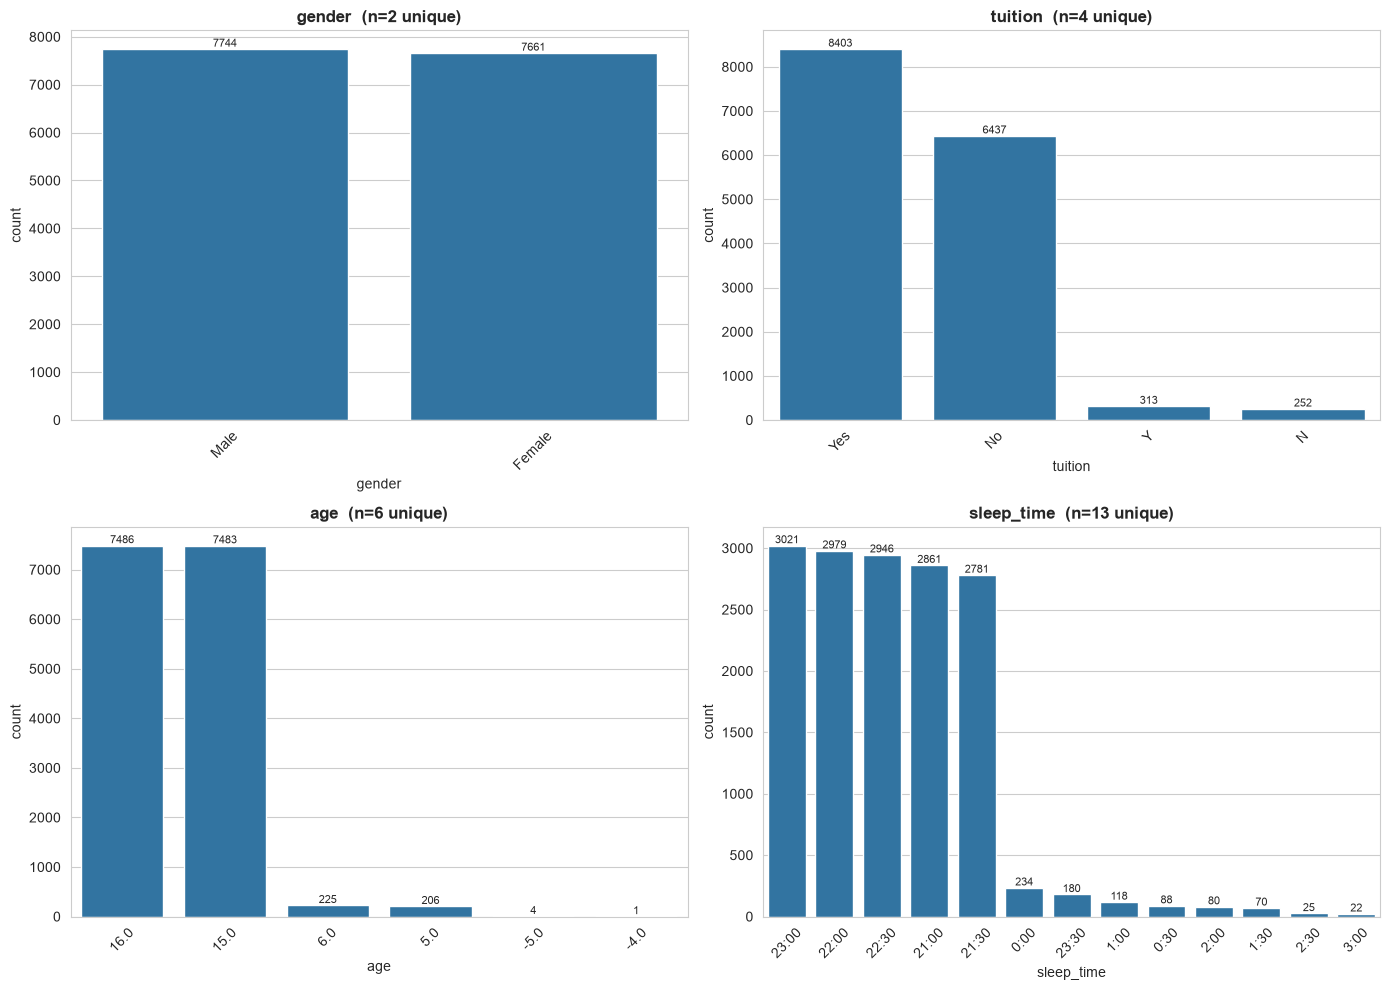

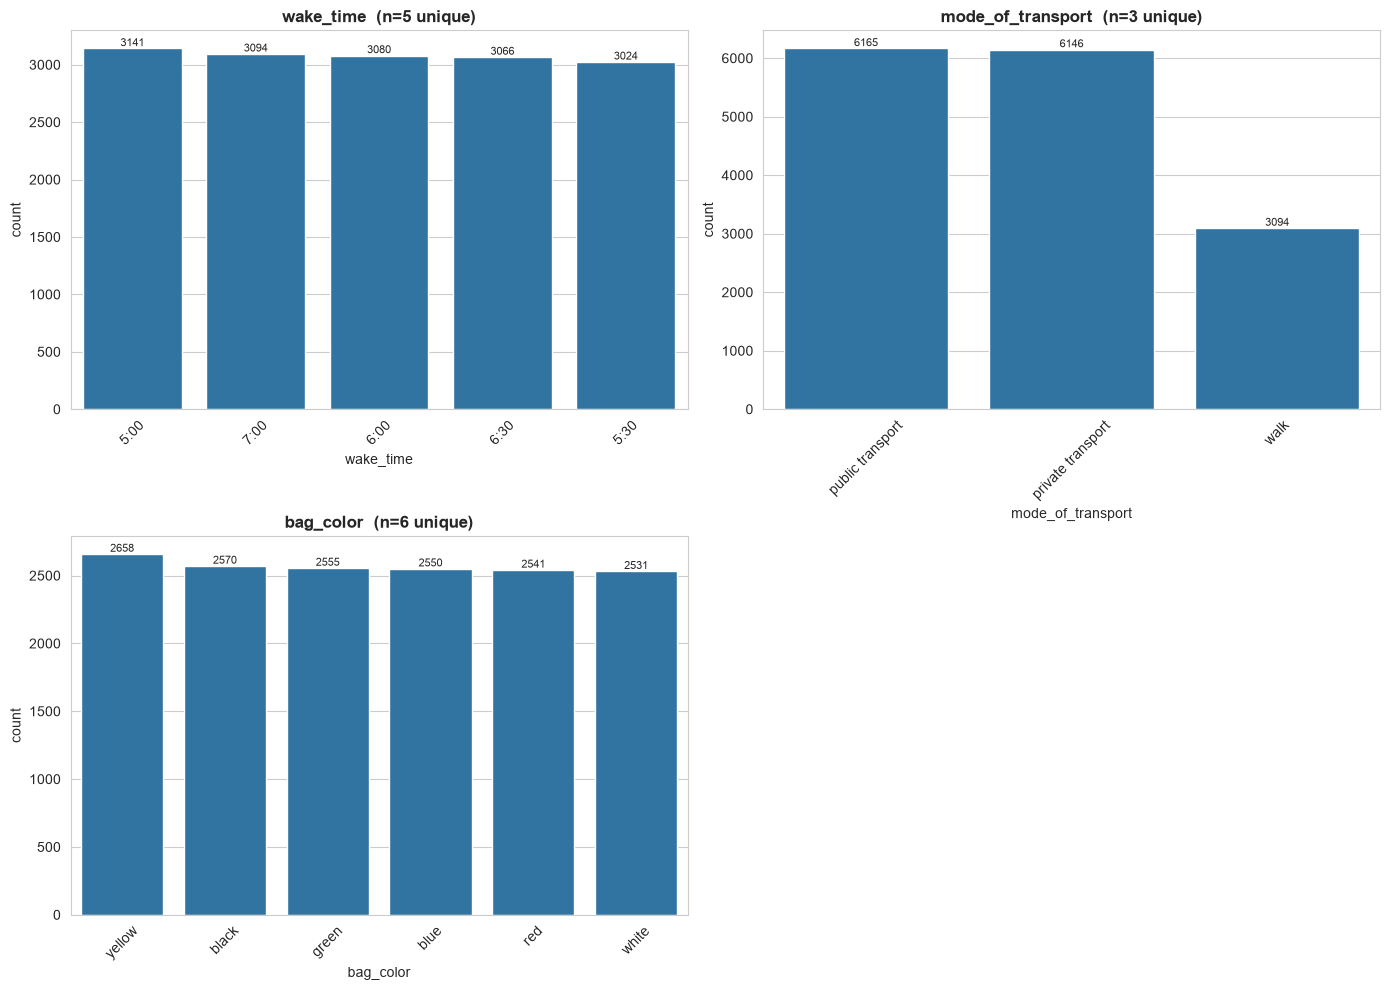

In [35]:

sns.set_style("whitegrid")

MAX_CATEGORIES = 20   # skip / trim columns with more unique values than this

cat_cols = df.columns.tolist()

# Drop columns that are too high-cardinality to be useful as bar charts
cat_cols = [c for c in cat_cols if df[c].nunique() <= MAX_CATEGORIES]

print(f"Plotting {len(cat_cols)} columns: {cat_cols}")

BATCH_SIZE = 4          # 2 per row x 2 rows per figure
n_per_row = 2

for start in range(0, len(cat_cols), BATCH_SIZE):
    batch = cat_cols[start:start + BATCH_SIZE]
    n_rows = math.ceil(len(batch) / n_per_row)

    fig, axes = plt.subplots(n_rows, n_per_row, figsize=(14, 5 * n_rows))
    axes = axes.flatten()

    for i, col in enumerate(batch):
        ax = axes[i]
        order = df[col].value_counts().index          # sorted by frequency
        sns.countplot(x=col, data=df, ax=ax, order=order)
        ax.set_title(f'{col}  (n={df[col].nunique()} unique)', fontsize=12, fontweight='bold')
        ax.tick_params(axis='x', rotation=45)
        for p in ax.patches:
            h = p.get_height()
            if h > 0:
                ax.annotate(f'{int(h)}',
                            (p.get_x() + p.get_width()/2., h),
                            ha='center', va='bottom', fontsize=8)

    for j in range(len(batch), len(axes)):
        axes[j].set_visible(False)

    plt.tight_layout()
    plt.show()
    plt.close(fig)      # <- frees memory, prevents accumulation

**From the bar chart output, there are several columns with mislabelled data. In the tuition column there are entries with "Y" and "N" that should be labelled "Yes" and "No". In the age column there are 5 entries with negative values**
**that should be removed and students with ages 5 and 6 that should not be taking O levels. In the CCA column there are entries with fully capitalised names of the CCA labels they represent.**

### Standardising Categorical Labels

In [36]:
# Replace "Y" and "N" to "Yes" and "No" in 'tuition' column
df ['tuition'] = df['tuition'].replace('Y', 'Yes')
df ['tuition'] = df['tuition'].replace('N', 'No')

# Assuming the ages 5 and 6 were meant to be data collected as ages 15 and 16 (Appropriate age for taking O levels), ages 5 and 6 will be replaced with 15 and 16 respectively. Assuming -5 was an supposed to represent 15, it is also replaced with 15. 
# However the single entry with age -4 is regarded as an erroneous entry and can be removed without significant impact on the data
df['age'] = df['age'].replace(5, 15)
df['age'] = df['age'].replace(6, 16)
df['age'] = df['age'].replace(-5, 15)
df= df[df['age'] != -4]

# Replace labels in column CCA with fully uncapitalised letters to avoid misclassification
df['CCA'] = df['CCA'].str.lower()
